<a href="https://colab.research.google.com/github/AsifZaman777/captcha-breaker-ocr-accuracy/blob/main/Captcha_breaker_RnD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

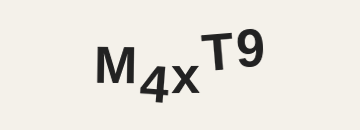

Predicted Captcha: M4xT9


In [48]:
from transformers import VisionEncoderDecoderModel, TrOCRProcessor
import torch
from PIL import Image
from IPython.display import display

# ocr loading with base model
processor = TrOCRProcessor.from_pretrained("anuashok/ocr-captcha-v3")
model = VisionEncoderDecoderModel.from_pretrained("anuashok/ocr-captcha-v3")

# Load and preprocess image
image_path = "/content/02_wave_baseline.png"
image = Image.open(image_path).convert("RGBA")

# create white bg to convert transparent pixels if any
background = Image.new("RGBA", image.size, (255, 255, 255))
combined = Image.alpha_composite(background, image).convert("RGB")

#prepare image
pixel_values = processor(combined, return_tensors="pt").pixel_values

#text generation
generated_ids = model.generate(pixel_values)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

#predict
display(image)
print("Predicted Captcha:", generated_text)

In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
#lets test with the fine tuned model of the base model
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("image-text-to-text", model="dathuynh1108/ocr-captcha-v3-finetuned")

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

In [40]:
# pip install -U transformers accelerate
# Load model directly
from transformers import AutoTokenizer, AutoModelForMultimodalLM

tokenizer = AutoTokenizer.from_pretrained("dathuynh1108/ocr-captcha-v3-finetuned")
model = AutoModelForMultimodalLM.from_pretrained("dathuynh1108/ocr-captcha-v3-finetuned", device_map="auto")

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

File: 01_warped_mono.png


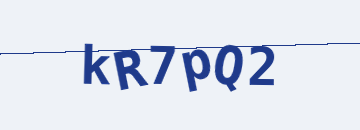

Predicted Captcha Fine-tuned (dathuynh1108): KR7pQ2
--------------------------------------------------
File: 02_wave_baseline.png


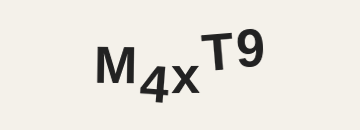

Predicted Captcha Fine-tuned (dathuynh1108): M4xT9
--------------------------------------------------
File: 03_multicolor_serif.png


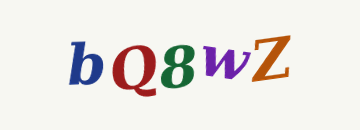

Predicted Captcha Fine-tuned (dathuynh1108): bQ8vZ
--------------------------------------------------
File: 04_digits_speckle.png


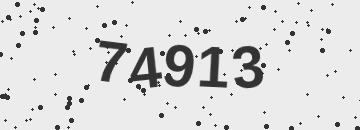

Predicted Captcha Fine-tuned (dathuynh1108): ,74913
--------------------------------------------------
File: 05_outlined.png


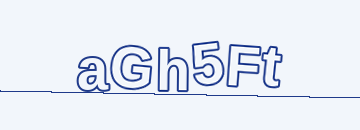

Predicted Captcha Fine-tuned (dathuynh1108): aGh5Ft
--------------------------------------------------
File: 06_tall_stretch.png


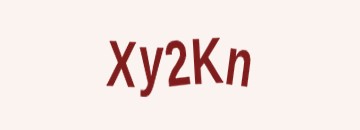

Predicted Captcha Fine-tuned (dathuynh1108): Xy2Kn
--------------------------------------------------
File: 07_strike_lines.png


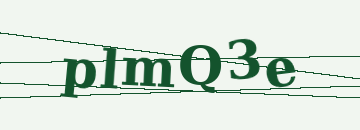

Predicted Captcha Fine-tuned (dathuynh1108): ph03e
--------------------------------------------------
File: 08_drop_shadow.png


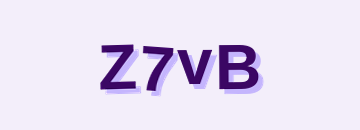

Predicted Captcha Fine-tuned (dathuynh1108): zz7VB
--------------------------------------------------
File: 09_overlapping.png


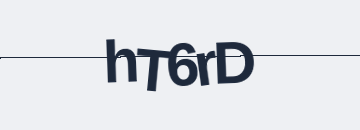

Predicted Captcha Fine-tuned (dathuynh1108): hr6D
--------------------------------------------------
File: 10_two_words.png


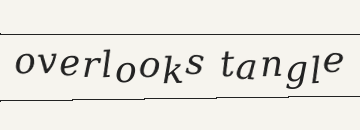

Predicted Captcha Fine-tuned (dathuynh1108): overLOKS tANGle
--------------------------------------------------
File: 11_hatch_overlay.png


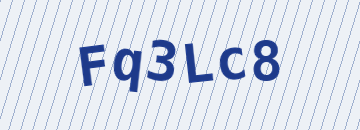

Predicted Captcha Fine-tuned (dathuynh1108): Fq3LC8
--------------------------------------------------
File: 12_warm_background.png


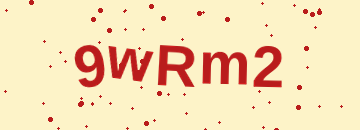

Predicted Captcha Fine-tuned (dathuynh1108): 9WRM2
--------------------------------------------------
File: 13_mixed_sizes.png


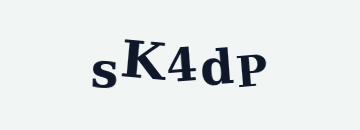

Predicted Captcha Fine-tuned (dathuynh1108): sK4dP
--------------------------------------------------
File: 14_skewed.png


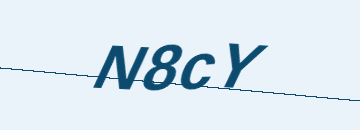

Predicted Captcha Fine-tuned (dathuynh1108): W8CY
--------------------------------------------------
File: 15_lines_and_dots.png


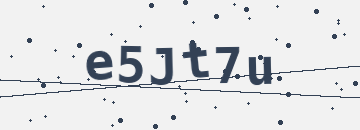

Predicted Captcha Fine-tuned (dathuynh1108): ee5Jt7u
--------------------------------------------------
File: 16_alternating_case.png


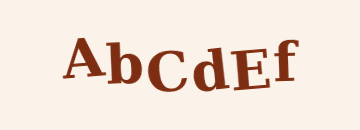

Predicted Captcha Fine-tuned (dathuynh1108): AbCdEf
--------------------------------------------------
File: 17_digits_on_grid.png


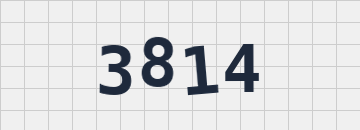

Predicted Captcha Fine-tuned (dathuynh1108): F3814
--------------------------------------------------
File: 18_mirrored_letters.png


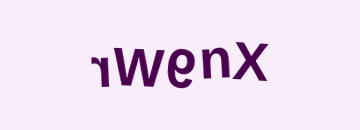

Predicted Captcha Fine-tuned (dathuynh1108): 1WenX
--------------------------------------------------
File: 19_low_contrast.png


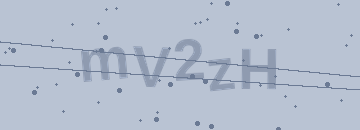

Predicted Captcha Fine-tuned (dathuynh1108): INV2zH
--------------------------------------------------
File: 20_handwritten_style.png


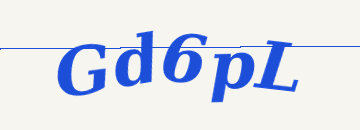

Predicted Captcha Fine-tuned (dathuynh1108): Gd6pL
--------------------------------------------------
File: 21_custom.png


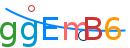

Predicted Captcha Fine-tuned (dathuynh1108): ggEnB6
--------------------------------------------------


In [61]:
# now use the finetuned model to predict png files
import glob
import os
from PIL import Image
from IPython.display import display

# Find all local captcha png images in /content/drive_captchas/
captcha_files = sorted(glob.glob("/content/drive_captchas/*.png"))

for file_path in captcha_files:
    filename = os.path.basename(file_path)
    print(f"File: {filename}")
    try:
        # Load image
        image = Image.open(file_path).convert("RGBA")

        # Create white background to convert transparent pixels if any
        background = Image.new("RGBA", image.size, (255, 255, 255))
        combined = Image.alpha_composite(background, image).convert("RGB")

        pixel_values = processor(combined, return_tensors="pt").pixel_values
        pixel_values = pixel_values.to(model.device)

        # Generate using fine-tuned model
        generated_ids = model.generate(pixel_values)
        generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

        # Display results
        display(image)
        print("Predicted Captcha Fine-tuned (dathuynh1108):", generated_text)
        print("-" * 50)
    except Exception as e:
        print(f"Error processing {filename}: {e}")

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

File: 01_warped_mono.png


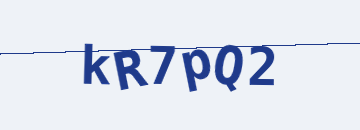

Predicted captcha (emelnov): k8ypo2
File: 02_wave_baseline.png


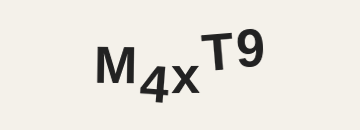

Predicted captcha (emelnov): m4xto
File: 03_multicolor_serif.png


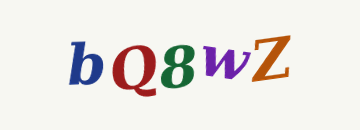

Predicted captcha (emelnov): bo8ux
File: 04_digits_speckle.png


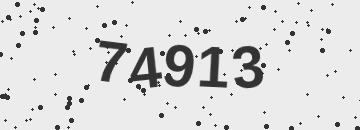

Predicted captcha (emelnov): 74913
File: 05_outlined.png


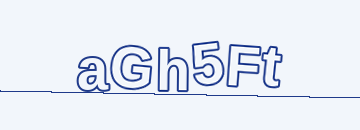

Predicted captcha (emelnov): a6h5pt
File: 06_tall_stretch.png


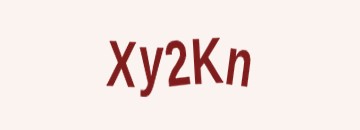

Predicted captcha (emelnov): xy2kn
File: 07_strike_lines.png


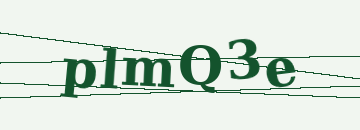

Predicted captcha (emelnov): cho8e
File: 08_drop_shadow.png


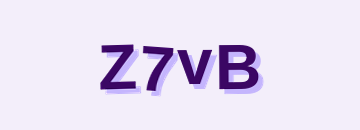

Predicted captcha (emelnov): z7vb
File: 09_overlapping.png


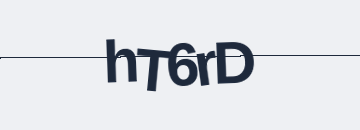

Predicted captcha (emelnov): ht6b
File: 10_two_words.png


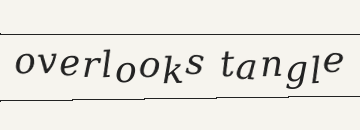

Predicted captcha (emelnov): ochostate
File: 11_hatch_overlay.png


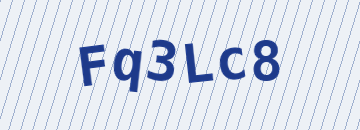

Predicted captcha (emelnov): t931c8
File: 12_warm_background.png


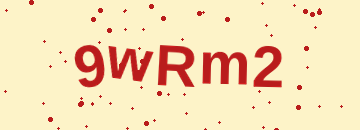

Predicted captcha (emelnov): 9WRm2
File: 13_mixed_sizes.png


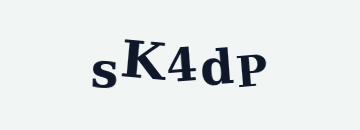

Predicted captcha (emelnov): sk4up
File: 14_skewed.png


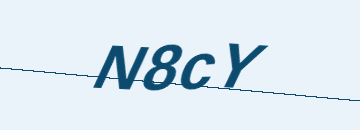

Predicted captcha (emelnov): a8cx
File: 15_lines_and_dots.png


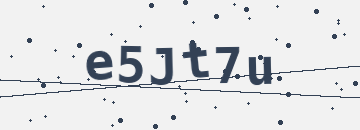

Predicted captcha (emelnov): e5tzu
File: 16_alternating_case.png


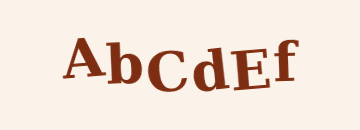

Predicted captcha (emelnov): abcaet
File: 17_digits_on_grid.png


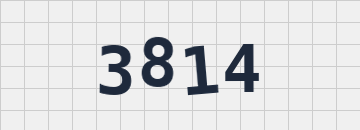

Predicted captcha (emelnov): 3814
File: 18_mirrored_letters.png


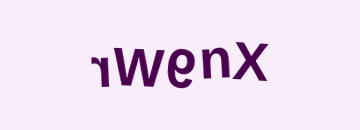

Predicted captcha (emelnov): 1wenx
File: 19_low_contrast.png


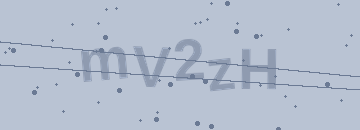

Predicted captcha (emelnov): my2t
File: 20_handwritten_style.png


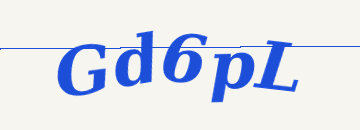

Predicted captcha (emelnov): 6d6pz
File: 21_custom.png


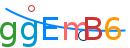

Predicted captcha (emelnov): o9eeb6


In [62]:
# use another f_tune model
import glob
import os
import torch
import math
from PIL import Image
import matplotlib.pyplot as plt
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# Загрузка модели и процессора
model_name = "emelnov/ocr-captcha-v4-mailru"
new_processor = TrOCRProcessor.from_pretrained(model_name)
new_model = VisionEncoderDecoderModel.from_pretrained(model_name).to(
    torch.device("cuda" if torch.cuda.is_available() else "cpu")
)

# Find all local captcha png images in /content/
captcha_files = sorted(glob.glob("/content/drive_captchas/*.png"))


# Prepare to store results for grid plotting
results = []

for file_path in captcha_files:
    filename = os.path.basename(file_path)
    print(f"File: {filename}")
    try:
        # Load image
        image = Image.open(file_path).convert("RGBA")

        # Create white background to convert transparent pixels if any
        background = Image.new("RGBA", image.size, (255, 255, 255))
        combined = Image.alpha_composite(background, image).convert("RGB")

        # Prepare image
        pixel_values = new_processor(images=combined, return_tensors="pt").pixel_values.to(new_model.device)

        # Generate text using the new model
        new_model.eval()
        with torch.no_grad():
            output_ids = new_model.generate(pixel_values)
        predicted_text = new_processor.batch_decode(output_ids, skip_special_tokens=True)[0]
        display(image)
        print("Predicted captcha (emelnov):", predicted_text)
    except Exception as e:
        print(f"Error processing {filename}: {e}")

# # Plot the images 5 in a row
# num_images = len(results)
# cols = 4
# rows = math.ceil(num_images / cols)

# fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
# axes = axes.flatten()  # Flatten in case we have a 2D grid

# for i in range(len(axes)):
#     if i < num_images:
#         img, filename, pred = results[i]
#         axes[i].imshow(img)
#         axes[i].set_title(f"{filename}\nPred: {pred}", fontsize=10)
#         axes[i].axis("off")
#     else:
#         axes[i].axis("off")  # Hide unused subplots

# plt.tight_layout()
# plt.show()


In [56]:
import glob
import os
import pandas as pd
import torch
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, AutoTokenizer, AutoModelForMultimodalLM

# Define ground truth mapping
ground_truth = {
    "01_warped_mono.png": "kR7pQ2",
    "02_wave_baseline.png": "M4xT9",
    "03_multicolor_serif.png": "bQ8wZ",
    "04_digits_speckle.png": "74913",
    "05_outlined.png": "aGh5Ft",
    "06_tall_stretch.png": "Xy2Kn",
    "07_strike_lines.png": "plmQ3e",
    "08_drop_shadow.png": "Z7vB",
    "09_overlapping.png": "hT6rD",
    "10_two_words.png": "overlooks tangle",
    "11_hatch_overlay.png": "Fq3Lc8",
    "12_warm_background.png": "9wRm2",
    "13_mixed_sizes.png": "sK4dP",
    "14_skewed.png": "N8cY",
    "15_lines_and_dots.png": "e5Jt7u",
    "16_alternating_case.png": "AbCdEf",
    "17_digits_on_grid.png": "3814",
    "18_mirrored_letters.png": "rWenX",
    "19_low_contrast.png": "mV2zH",
    "20_handwritten_style.png": "Gd6pL",
    "21_custom.png": "ggEmB6"
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Base Model Setup
base_processor = TrOCRProcessor.from_pretrained("anuashok/ocr-captcha-v3")
base_model = VisionEncoderDecoderModel.from_pretrained("anuashok/ocr-captcha-v3").to(device)
base_model.eval()

# 2. First Fine-tuned Model Setup
ft1_processor = TrOCRProcessor.from_pretrained("anuashok/ocr-captcha-v3")
ft1_model = VisionEncoderDecoderModel.from_pretrained("dathuynh1108/ocr-captcha-v3-finetuned").to(device)
ft1_model.eval()

# 3. Second Fine-tuned Model Setup
ft2_processor = TrOCRProcessor.from_pretrained("emelnov/ocr-captcha-v4-mailru")
ft2_model = VisionEncoderDecoderModel.from_pretrained("emelnov/ocr-captcha-v4-mailru").to(device)
ft2_model.eval()

# Load files
captcha_files = sorted(glob.glob("/content/drive_captchas/*.png"))
evaluation_results = []

for file_path in captcha_files:
    filename = os.path.basename(file_path)
    if filename not in ground_truth:
        continue

    true_text = ground_truth[filename]

    try:
        # Load image with white background conversion
        image = Image.open(file_path).convert("RGBA")
        background = Image.new("RGBA", image.size, (255, 255, 255))
        combined = Image.alpha_composite(background, image).convert("RGB")

        # Predict using Base Model
        pixels_base = base_processor(combined, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            ids_base = base_model.generate(pixels_base)
        pred_base = base_processor.batch_decode(ids_base, skip_special_tokens=True)[0]

        # Predict using First Fine-tuned Model (dathuynh1108)
        pixels_ft1 = ft1_processor(combined, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            ids_ft1 = ft1_model.generate(pixels_ft1)
        pred_ft1 = ft1_processor.batch_decode(ids_ft1, skip_special_tokens=True)[0]

        # Predict using Second Fine-tuned Model (emelnov)
        pixels_ft2 = ft2_processor(images=combined, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            ids_ft2 = ft2_model.generate(pixels_ft2)
        pred_ft2 = ft2_processor.batch_decode(ids_ft2, skip_special_tokens=True)[0]

        evaluation_results.append({
            "Filename": filename,
            "Ground Truth": true_text,
            "Base Model": pred_base,
            "FT Model 1 (dathuynh1108)": pred_ft1,
            "FT Model 2 (emelnov)": pred_ft2
        })
    except Exception as e:
        print(f"Error evaluating {filename}: {e}")

# Convert to DataFrame and Display
df_eval = pd.DataFrame(evaluation_results)

# Calculate exact match accuracy for each model
acc_base = (df_eval["Base Model"] == df_eval["Ground Truth"]).mean() * 100
acc_ft1 = (df_eval["FT Model 1 (dathuynh1108)"] == df_eval["Ground Truth"]).mean() * 100
acc_ft2 = (df_eval["FT Model 2 (emelnov)"] == df_eval["Ground Truth"]).mean() * 100

print(f"--- Accuracy (Exact Match) ---")
print(f"Base Model: {acc_base:.2f}%")
print(f"FT Model 1 (dathuynh1108): {acc_ft1:.2f}%")
print(f"FT Model 2 (emelnov): {acc_ft2:.2f}%")
print("-" * 50)

# Render full comparison table
pd.set_option('display.max_rows', None)
display(df_eval)

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

--- Accuracy (Exact Match) ---
Base Model: 28.57%
FT Model 1 (dathuynh1108): 23.81%
FT Model 2 (emelnov): 9.52%
--------------------------------------------------


,Filename,Ground Truth,Base Model,FT Model 1 (dathuynh1108),FT Model 2 (emelnov)
0,01_warped_mono.png,kR7pQ2,KR7pQ2,KR7p2,k8ypo2
1,02_wave_baseline.png,M4xT9,M4xT9,M4xT9,m4xto
2,03_multicolor_serif.png,bQ8wZ,bQ8vZ,bQ8wZ,bo8ux
3,04_digits_speckle.png,74913,",74913",74913,74913
4,05_outlined.png,aGh5Ft,aGh5Ft,a6h5FI,a6h5pt
5,06_tall_stretch.png,Xy2Kn,Xy2Kn,xy2kn,xy2kn
6,07_strike_lines.png,plmQ3e,ph03e,pm03e,cho8e
7,08_drop_shadow.png,Z7vB,zz7VB,Z7VB,z7vb
8,09_overlapping.png,hT6rD,hr6D,hr6rD,ht6b
9,10_two_words.png,overlooks tangle,overLOKS tANGle,erkangle,ochostate


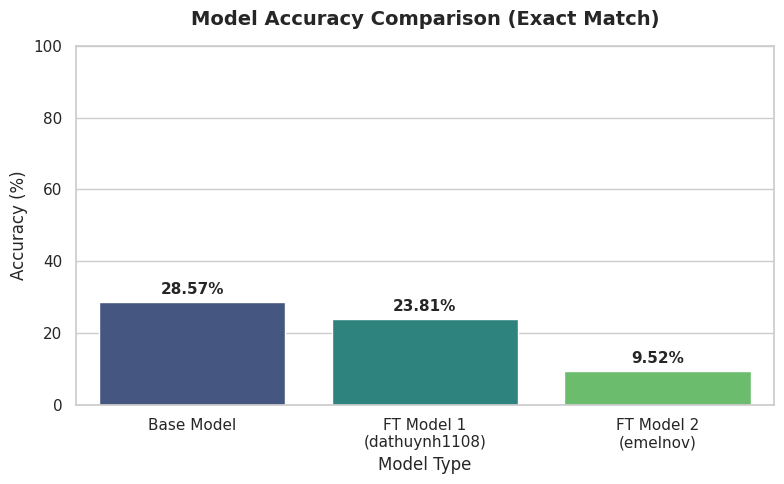

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
model_names = ['Base Model', 'FT Model 1\n(dathuynh1108)', 'FT Model 2\n(emelnov)']
accuracies = [acc_base, acc_ft1, acc_ft2]

# Create the bar chart
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Generate bar plot
ax = sns.barplot(x=model_names, y=accuracies, palette="viridis", hue=model_names, legend=False)

# Add values on top of the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Title and Labels
plt.title("Model Accuracy Comparison (Exact Match)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Model Type", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.ylim(0, 100)

# Show plot
plt.tight_layout()
plt.show()